# Logistic regression: predicting whether adolescents cross the BDI-II threshold

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

Logistic regression predicts the probability that an adolescent is above the threshold, and labels them "depressed" when that probability is 0.5 or more.

---
## Step 1. Load data, define target and features

The target is `depressed`, the binary version of `bdi_total` (1 if the BDI-II total is 14 or above, the threshold for at least mild depression). This answers the group's research question directly: whether adolescents cross the clinical threshold.

The features are the same seven used in the final linear regression model, after the multicollinearity fixes: the raw `_1to6` screen-time items and the raw `sqi_*` sleep items are excluded, and `bdi_total` and the `bdi_item_*` columns are excluded because `depressed` is derived from them.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/processed/model_ready.csv")

# Same feature set as the final linear regression model in modelling.ipynb
feature_cols = [
    "screen_time_index", "est_leisure_screen_hours", "sex_binary",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours",
]
target = "depressed"   # 1 = BDI-II total >= 14, 0 = below

X = df[feature_cols]
y = df[target].astype(int)

print("X shape:", X.shape)
print(y.value_counts().rename({0: "not depressed", 1: "depressed"}))

X shape: (4810, 7)
depressed
not depressed    4023
depressed         787
Name: count, dtype: int64


---
## Step 2. Train/test split

In [3]:
# Same split settings as modelling.ipynb, so the test set is the same adolescents
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 3848
Test observations: 962


---
## Step 3. Fit the logistic regression model

`max_iter` is raised from the default so the solver has enough iterations to converge on unscaled features.

In [4]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

coefficients = pd.Series(model.coef_[0], index=feature_cols)
print("Intercept:", round(model.intercept_[0], 3))
print(coefficients.sort_values().round(3))

Intercept: -4.573
est_leisure_screen_hours   -0.136
avg_sleep_hours            -0.084
social_jetlag_hours        -0.016
midsleep_weekend_hours      0.138
screen_time_index           0.405
sleep_quality_index         0.696
sex_binary                  1.023
dtype: float64


## **Explanation**

_To fill in after running._ A positive coefficient means a higher value of that feature raises the odds of being above the threshold; a negative one lowers them. Unlike linear regression, the coefficients are in log-odds, not BDI points.

---
## Step 4. Evaluate on the test set

Accuracy is compared with a baseline of always predicting "not depressed". Because most adolescents are below the threshold, that baseline is already high, so accuracy on its own can be misleading.

In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred = model.predict(X_test)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
baseline_acc = (y_test == 0).mean()

print(f"Training accuracy: {train_acc:.1%}")
print(f"Test accuracy:     {test_acc:.1%}")
print(f"Baseline (always 'not depressed'): {baseline_acc:.1%}")

Training accuracy: 83.9%
Test accuracy:     84.9%
Baseline (always 'not depressed'): 84.8%


               precision    recall  f1-score   support

not depressed       0.87      0.97      0.92       816
    depressed       0.51      0.16      0.24       146

     accuracy                           0.85       962
    macro avg       0.69      0.57      0.58       962
 weighted avg       0.81      0.85      0.81       962



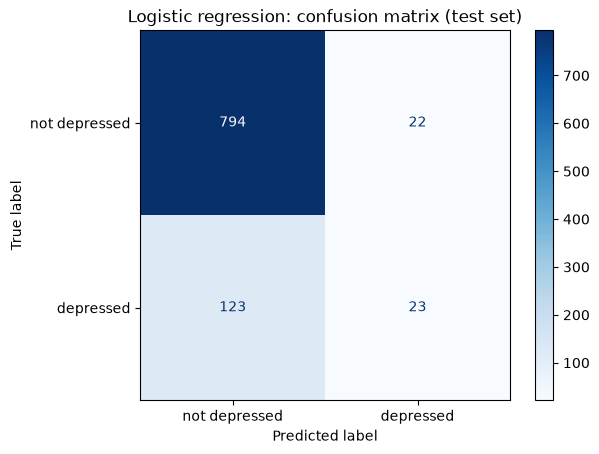

In [6]:
print(classification_report(y_test, y_pred, target_names=["not depressed", "depressed"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["not depressed", "depressed"], cmap="Blues"
)
plt.title("Logistic regression: confusion matrix (test set)")
plt.show()

## **Explanation**

_To fill in after running: compare test accuracy with the baseline, and read the recall for the "depressed" row of the classification report, which is the share of real cases above the threshold that the model catches._

---
## Step 5. Save results for the comparison notebook

In [7]:
import os
os.makedirs("../results", exist_ok=True)

pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_pred,
    "prob_depressed": model.predict_proba(X_test)[:, 1],
}, index=y_test.index).to_csv("../results/logreg_predictions.csv", index_label="row")

print("Saved ../results/logreg_predictions.csv")

Saved ../results/logreg_predictions.csv
